## Color analysis

In [1]:
import sys
from pathlib import Path

current_dir = Path.cwd()
proj_dir = current_dir.parent.parent.resolve() # get project root directory

print(f"Project directory set to: {proj_dir}")

# Add the project root to the system path to import local modules
sys.path.append(str(proj_dir / 'python'))

Project directory set to: C:\Users\z004ps0b\Documents\dermascan


In [2]:
from dataset_manager import DatasetManager
from abcd_algorithms.mask_utils import create_simple_binary_mask, boundary_extraction
from abcd_algorithms.color_scorer import analyze_lesion_colors
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from skimage import io

In [ ]:
# load the dataset manager
dataset_manager = DatasetManager(data_dir=str(proj_dir / "data"))

# load the dataset
# dataset = dataset_manager.load_dataset()
dataset_manager.load_cleaned_metadata()

### Get specific image from dataset, extract binary mask, and outline

In [4]:
# load specific sample image and display image id, lesions type image with outlien mask and rotated binary mask with centroid
image_id, lesion_type, image = dataset_manager.get_sample_image()

binary_mask = create_simple_binary_mask(image=image)

outline = boundary_extraction(binary_mask)

outline_overlay = image.copy()
outline_overlay[outline > 0] = [0, 255, 0]

In [5]:
# Overlay the binary mask on the original image and keep only the colors in the lesion area
lesion_area = np.zeros_like(image)
lesion_area[binary_mask == 255] = image[binary_mask == 255]

Color uniformity analysis:
     Score: 0.5083235987952428
     Number of colors: 112
     Entropy: 5.805397775824559


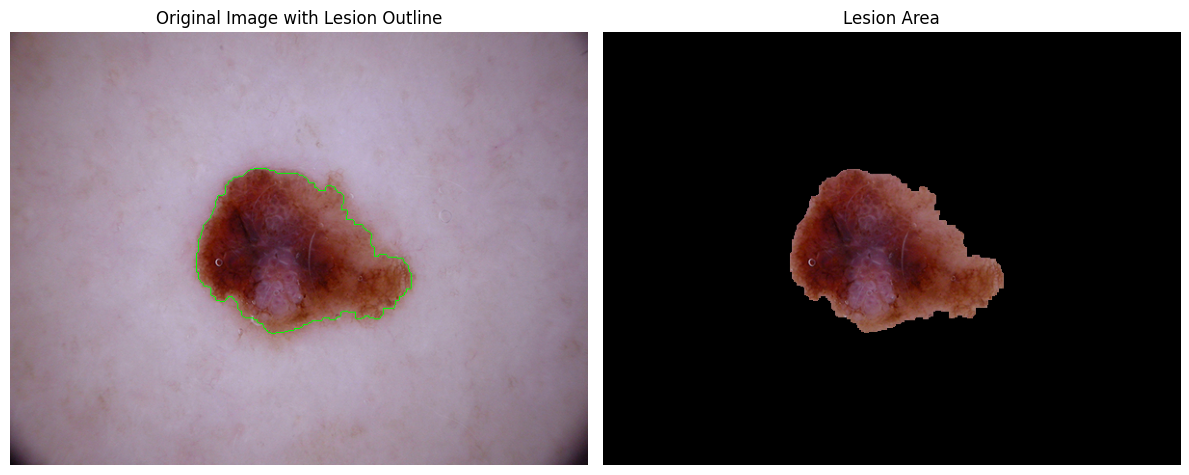

In [6]:
score, effective_colors, entropy = analyze_lesion_colors(image=image, mask=binary_mask)

print("Color uniformity analysis:")
print(f"     Score: {score}")
print(f"     Number of colors: {effective_colors}")
print(f"     Entropy: {entropy}")

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].imshow(outline_overlay)
axes[0].set_title('Original Image with Lesion Outline')
axes[0].axis('off')

axes[1].imshow(lesion_area)
axes[1].set_title('Lesion Area')
axes[1].axis('off')

plt.tight_layout()
plt.show()


Color Uniformity Comparison by Lesion Type:
            color_score                         effective_colors               \
                   mean     std     min     max             mean      std min   
lesion_type                                                                     
mel              0.5758  0.0491  0.4479  0.7579          91.0307  47.0502   5   
nv               0.6036  0.0387  0.5058  0.8378          64.7419  26.8598   3   

                 entropy                          
             max    mean     std     min     max  
lesion_type                                       
mel          304  4.8307  0.8630  1.7729  7.3140  
nv           248  4.3365  0.6199  1.0683  6.3594  


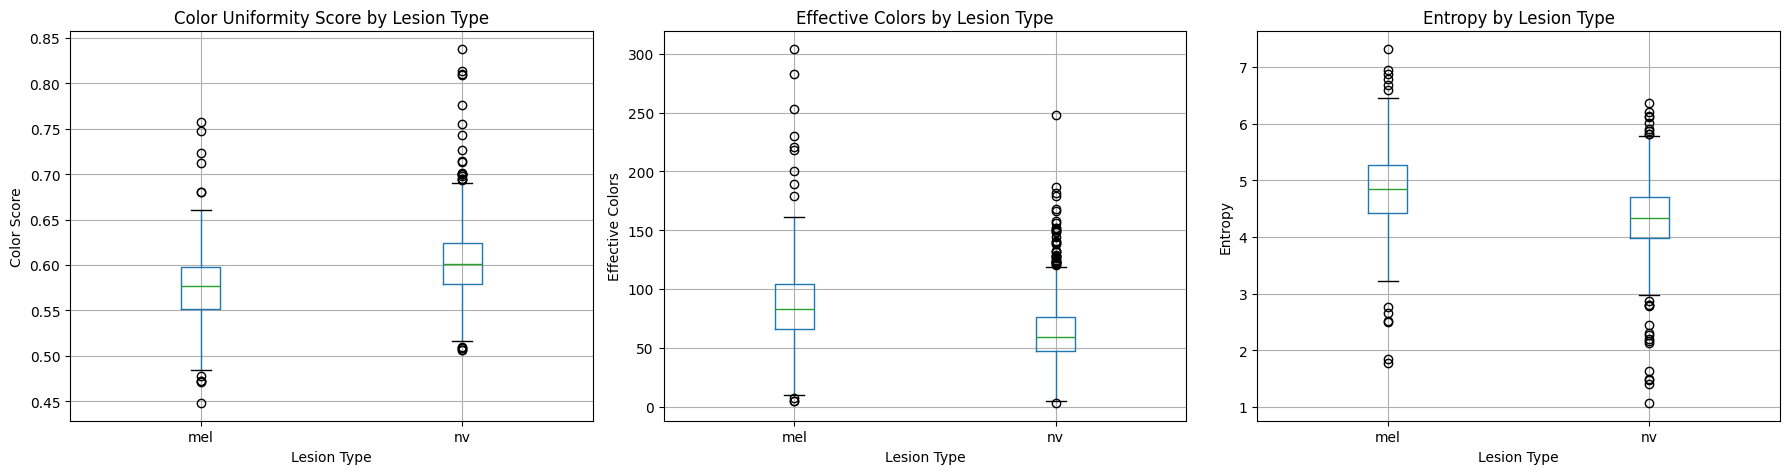


Correlation Matrix:
                  color_score  effective_colors   entropy
color_score          1.000000         -0.759920 -0.972646
effective_colors    -0.759920          1.000000  0.875063
entropy             -0.972646          0.875063  1.000000


In [7]:
# Compare color uniformity score, effective colors, and entropy across 1000 samples
comparison_samples = dataset_manager.get_n_samples(n=1000)
comparison_results = []

for i in range(len(comparison_samples)):
    image_id = comparison_samples.iloc[i]['image_id']
    lesion_type = comparison_samples.iloc[i]['dx']
    image_path = comparison_samples.iloc[i]['image_path']
    
    # Load image
    img = io.imread(image_path)
    
    # Create binary mask
    binary_mask = create_simple_binary_mask(image=img)
    
    # Analyze lesion colors
    color_score, effective_colors, entropy = analyze_lesion_colors(image=img, mask=binary_mask)
    
    # Store results
    comparison_results.append({
        'image_id': image_id,
        'lesion_type': lesion_type,
        'color_score': color_score,
        'effective_colors': effective_colors,
        'entropy': entropy
    })

# Create DataFrame
comparison_df = pd.DataFrame(comparison_results)

# Calculate statistics by lesion type
comparison_stats = comparison_df.groupby('lesion_type').agg({
    'color_score': ['mean', 'std', 'min', 'max'],
    'effective_colors': ['mean', 'std', 'min', 'max'],
    'entropy': ['mean', 'std', 'min', 'max']
}).round(4)

print("\nColor Uniformity Comparison by Lesion Type:")
print(comparison_stats)

# Visualize the comparison
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Box plot for color score
comparison_df.boxplot(column='color_score', by='lesion_type', ax=axes[0])
axes[0].set_title('Color Uniformity Score by Lesion Type')
axes[0].set_xlabel('Lesion Type')
axes[0].set_ylabel('Color Score')

# Box plot for effective colors
comparison_df.boxplot(column='effective_colors', by='lesion_type', ax=axes[1])
axes[1].set_title('Effective Colors by Lesion Type')
axes[1].set_xlabel('Lesion Type')
axes[1].set_ylabel('Effective Colors')

# Box plot for entropy
comparison_df.boxplot(column='entropy', by='lesion_type', ax=axes[2])
axes[2].set_title('Entropy by Lesion Type')
axes[2].set_xlabel('Lesion Type')
axes[2].set_ylabel('Entropy')

plt.suptitle('')
plt.tight_layout()
plt.show()

# Calculate correlation between metrics
correlation = comparison_df[['color_score', 'effective_colors', 'entropy']].corr()
print("\nCorrelation Matrix:")
print(correlation)